# Lab 09: How to build an agent from LangChain's pieces

**Notebook 1 of 2: meet LangChain's pieces on four small jobs**

## Goal

Meet LangChain one piece at a time, on four small jobs for a friend called Maya: write her a birthday message,
turn her dinner invitation into a calendar entry, count the days to her birthday, and find out what the weather is
usually like on that day in the Grand Canyon. The first job needs a chat model, a prompt template and a parser, joined into
a **chain**. The second needs a typed output. The third needs something the model does not have, Maya's birthday,
so we give it tools and let `create_agent` run the loop. The fourth needs the web, so the agent gets a search tool
that the model's provider runs, beside our own.
Nothing here touches the music shop yet. This notebook is the playground; notebook 2 takes the same pieces to the
Chinook support desk.

## What you will learn

- How to call a chat model with `ChatOpenAI` and read the `AIMessage` it returns.
- How a prompt template, a model and an output parser join into a chain with `|`, and how to see the chain's steps.
- How to get a typed object instead of text with `with_structured_output`, and what the type checks and does not
  check.
- How to turn a Python function into a tool, and how to make one round trip by hand: the model asks for the tool,
  our code runs it and sends the result back.
- How `create_agent` runs that round trip as a loop, how to draw the agent's graph, and how to watch a run one step
  at a time with `stream`.
- How to give an agent a ready-made tool, web search, beside our own, and what its answer does and does not
  prove.
- How to swap the model in a chain for another vendor's (optional).

## Setup

The first cell is the same in every lab: it finds the repository folder, reads the model name from `models.env`, and
takes the key from `.env` without printing it.

In [1]:
from pathlib import Path
import json
import os
from dotenv import dotenv_values

# The repository folder is the first folder, from here upwards, that holds models.env
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "models.env").exists())

# Models and prices come from models.env; a non-empty value in .env replaces one of them
settings = dotenv_values(ROOT / "models.env")
local = dotenv_values(ROOT / ".env")
settings.update({name: value for name, value in local.items() if name in settings and value})

# The key comes from the environment or .env, and is never printed
os.environ.setdefault("OPENAI_API_KEY", local.get("OPENAI_API_KEY") or "")
assert os.environ["OPENAI_API_KEY"], "Put OPENAI_API_KEY in .env at the repository folder (copy .env.example)."

MODEL = settings["MODEL_DEFAULT"]
EFFORT = settings["REASONING_EFFORT"] or None
print("model:", MODEL, "| reasoning effort:", EFFORT, "| key found: yes")

model: gpt-6-luna | reasoning effort: none | key found: yes


---

## Part A: Write a birthday message with a model, a prompt template and a parser

Maya's birthday is coming, and we want a short message for her. One model call can write it. We make that call
first, then turn it into something we can reuse for any friend, one piece at a time.

### The chat model

In LangChain a model is an object. `ChatOpenAI`, from the `langchain-openai` package, is the one for OpenAI's
models. We give it:

- `model=MODEL`: the model name from `models.env`.
- `reasoning_effort=EFFORT`: how much the model may reason before it answers, also from `models.env`.
- `timeout=60`: give up on a request after 60 seconds, so a request that gets stuck fails quickly instead of
  freezing a cell.

Creating the object sends nothing. It only stores the settings.

In [2]:
from langchain_openai import ChatOpenAI

llm = ChatOpenAI(model=MODEL, reasoning_effort=EFFORT, timeout=60)

print(type(llm).__name__, "| model:", llm.model_name)

ChatOpenAI | model: gpt-6-luna


`invoke` sends one request and returns the model's reply.

In [3]:
reply = llm.invoke("Write a one-line birthday message for Maya, who loves hiking.")

print(type(reply).__name__)
print("text: ", reply.text)
print("usage:", reply.usage_metadata["input_tokens"], "tokens in,", reply.usage_metadata["output_tokens"], "tokens out")

AIMessage
text:  Happy birthday, Maya—may your year be full of beautiful trails, breathtaking views, and unforgettable adventures!
usage: 19 tokens in, 24 tokens out


- `reply.text` is the words of the reply. In our run: *Happy birthday, Maya—may your year be full of
  beautiful trails, breathtaking views, and unforgettable adventures!* Your wording will differ.
- `reply.usage_metadata` holds the token counts: 19 tokens in, 24 tokens out. Token counting is the subject
  of notebook 2; here it is enough to see that the object carries the numbers.

The message is for Maya, who loves hiking. For Sam, who loves chess, we would type the sentence again with two
words changed. A prompt template lets us state the sentence once with two named gaps, and fill them in for any
friend.

In [4]:
from langchain_core.prompts import ChatPromptTemplate

prompt = ChatPromptTemplate.from_template("Write a one-line birthday message for {name}, who loves {hobby}.")

print(type(prompt).__name__)
print("variables:", prompt.input_variables)

ChatPromptTemplate
variables: ['hobby', 'name']


The template found the two names inside the braces: `input_variables` is `['hobby', 'name']`, in alphabetical
order. It expects a value for each.

We fill a template with `invoke`, the same method name the model has. The input is a dictionary from variable name
to value.

In [5]:
filled = prompt.invoke({"name": "Sam", "hobby": "chess"})

print(type(filled).__name__)
for message in filled.to_messages():
    print(type(message).__name__, "|", message.content)

ChatPromptValue
HumanMessage | Write a one-line birthday message for Sam, who loves chess.


`invoke` returned a `ChatPromptValue`: the filled prompt. `to_messages()` shows what a model would receive. It is
one `HumanMessage`, a message from the user, and it holds our sentence with *Sam* and *chess* in the gaps.

Nothing was sent to the model. Filling a template is plain text work.

**What does a template check?** Only that every gap gets a value. We leave one out:

In [6]:
try:
    prompt.invoke({"name": "Sam"})
except KeyError as error:
    print("KeyError:", error.args[0].splitlines()[0])

KeyError: Input to ChatPromptTemplate is missing variables {'hobby'}.  Expected: ['hobby', 'name'] Received: ['name']


The template refuses, and names the gap that is missing: `{'hobby'}`. (`try` and `except KeyError` catch the
error so that we can print its first line and carry on.)

### The model, then the parser, one step at a time

Two steps are left: send the filled prompt to the model, then take the words out of the reply. We run each one by
hand before we join them, so that we have seen every object that passes from one step to the next.

The model accepts the filled prompt directly:

In [7]:
message = llm.invoke(filled)

print(type(message).__name__)

AIMessage


An `AIMessage` again. The code that uses the birthday message wants a string, to put in a text or an email. We
could write `message.text`. LangChain also has an object for this step, an **output parser**:
`StrOutputParser` takes a message and returns its text.

In [8]:
from langchain_core.output_parsers import StrOutputParser

parser = StrOutputParser()
text = parser.invoke(message)

print("is a str:", isinstance(text, str))
print(text)

is a str: True
Happy birthday, Sam—may your year be full of brilliant moves and checkmates!


A string. In our run it wished Sam a year of *brilliant moves* and *winning positions*.

In [9]:
chain = prompt | llm | parser

print(type(chain).__name__)
print([type(step).__name__ for step in chain.steps])

RunnableSequence
['ChatPromptTemplate', 'ChatOpenAI', 'StrOutputParser']


`prompt | llm | parser` built a `RunnableSequence`, which we call a **chain**. Its `steps` list holds our three
objects, in the order we wrote them.

Nothing ran. `|` only joins. The chain has `invoke` too: it takes what its first step takes, a dictionary.

In [10]:
print(chain.invoke({"name": "Sam", "hobby": "chess"}))

Happy birthday, Sam—may your year be full of brilliant moves and winning positions!


In our run the chain wished Sam a year *full of brilliant moves and winning positions*. It is a new model call, so the
words will differ from the earlier cell.

**Checkpoint A.** A birthday message for Maya from one `invoke` call; a `ChatPromptTemplate` with the variables
`['hobby', 'name']`; a `KeyError` that names `{'hobby'}`; a `RunnableSequence` with the steps
`['ChatPromptTemplate', 'ChatOpenAI', 'StrOutputParser']`; and a complete message for Sam that mentions chess.
Your wording will differ.

---

## Part B: Extract typed data with `with_structured_output`

Maya answers with a text message:

> Dinner at Maya's Thursday 7pm, bring dessert, tell Sam too

In [11]:
MESSAGE = "Dinner at Maya's Thursday 7pm, bring dessert, tell Sam too"

reply = llm.invoke(
    "Turn this text message into a calendar entry. "
    "Reply with JSON that has the keys title, day, time, bring and tell.\n\n" + MESSAGE
)

entry = json.loads(reply.text)
print(entry)

{'title': 'Dinner at Maya’s', 'day': 'Thursday', 'time': '7:00 PM', 'bring': 'Dessert', 'tell': 'Sam'}


`json.loads` worked: the reply was plain JSON, and it has the five keys we named. Now look at the values. The
time is `7:00 PM`, the way the message wrote it. And `tell` is the string `'Sam'`. We named the keys and said
nothing about what kind of value each one holds, so the model chose.

Now we use the entry. The invitation says to tell Sam, so our code goes through `tell` and sends each person a
text:

In [12]:
for person in entry["tell"]:
    print("Text the invitation to:", person)

Text the invitation to: S
Text the invitation to: a
Text the invitation to: m


Three texts, to *S*, *a* and *m*. No error was raised anywhere. Our loop expected `tell` to be a list of
names and got one string, and a `for` loop over a string goes through its letters.

We could add a sentence to the request (*tell must be a list*), then another for the time, and then check every
reply by hand to see whether the model followed them. A shape is easier to state once, in code, where it can be
checked.

### Say what we want as a class

Here is the entry we want, written by hand:

In [13]:
wanted = {"title": "Dinner at Maya's", "day": "Thursday", "time": "19:00", "bring": "dessert", "tell": ["Sam"]}
print(wanted)

{'title': "Dinner at Maya's", 'day': 'Thursday', 'time': '19:00', 'bring': 'dessert', 'tell': ['Sam']}


Five fields. Four are strings, and `tell` is a list of strings, with one name in it. The time is on the 24-hour
clock.

We describe that shape as a **Pydantic model**: a class that lists each field with its type.

- `title: str` means the field `title` must be a string.
- `tell: list[str]` means a list in which every item is a string.
- `Field(description=...)` adds a sentence about the field. The model reads it, so a description is an instruction
  and not a comment.

In [14]:
from pydantic import BaseModel, Field


class Event(BaseModel):
    """One entry for a calendar."""
    title: str = Field(description="What the event is, in a few words")
    day: str
    time: str = Field(description="Start time on the 24-hour clock, like 19:00")
    bring: str = Field(description="What to bring, or an empty string")
    tell: list[str] = Field(description="People to pass the invitation on to")

`with_structured_output(Event)` gives us a new object that wraps the model. When we call it, LangChain sends the
class to the API as the shape the reply must have, and builds an `Event` from what comes back. This time we send
only the text message, with no instructions around it.

In [15]:
extract = llm.with_structured_output(Event)

event = extract.invoke(MESSAGE)

print(type(event).__name__)
print(repr(event))

Event
Event(title="Dinner at Maya's", day='Thursday', time='19:00', bring='Dessert', tell=['Sam'])


An `Event` object. Read its fields against the entry we wanted:

- `tell` is `['Sam']`: a list with one name in it, as the class says.
- `time` is `19:00`: the description asked for the 24-hour clock, and the model followed it.
- `title` and `day` match. `bring` is `Dessert`, with a capital letter: the type says "a string" and nothing about
  capitals.

Python reads the fields as attributes, so the loop from before is now safe:

In [16]:
for person in event.tell:
    print("Text the invitation to:", person)

Text the invitation to: Sam


One text, to Sam.

### What the type checks, and what it does not

The class checks every value against its type. We make an entry by hand with two mistakes: the time as the number
`7`, and `tell` as one string.

In [17]:
from pydantic import ValidationError

try:
    Event(title="Dinner at Maya's", day="Thursday", time=7, bring="dessert", tell="Sam")
except ValidationError as error:
    for problem in error.errors():
        print(problem["loc"][0], "|", problem["msg"])

time | Input should be a valid string
tell | Input should be a valid list


Two problems, each named by its field: `time` should be a string, and `tell` should be a list. The class refuses
to build the entry. This is the check we did not have when we asked for JSON in words: there, the string `'Sam'`
went straight into our loop.

Now a different kind of mistake. We make an entry whose types are all correct, and add a guest:

In [18]:
made_up = Event(title="Dinner at Maya's", day="Thursday", time="19:00", bring="dessert", tell=["Sam", "Lina"])

print(repr(made_up))
print("everyone in tell is named in the message:", all(name in MESSAGE for name in made_up.tell))

Event(title="Dinner at Maya's", day='Thursday', time='19:00', bring='dessert', tell=['Sam', 'Lina'])
everyone in tell is named in the message: False


No error. The entry is a valid `Event`, and it is wrong: the message never mentions Lina.

The last line is a check of our own. `all(name in MESSAGE for name in made_up.tell)` asks, for every name in
`tell`, whether it appears in the text message. It prints `False`, because *Lina* does not.

**Key lesson:** a type checks the shape of an answer: every field present, each of the right type. It does not
check that the values are true. A model can return a well-typed entry with an invented guest as easily as we just
did, so a fact that matters still needs a check against its source.

**Checkpoint B.** JSON in words gives a dictionary whose `tell` is the string `'Sam'`, so the loop prints three
letters; `with_structured_output(Event)` gives an `Event` whose `tell` is the list `['Sam']` and whose `time` is
`19:00`; the entry with a number for the time is refused with two problems; the entry with Lina is accepted, and
our own check prints `False`.

---

## Part C: Give the model a tool, and make the round trip by hand once

The dinner is in the calendar. The birthday is the next job:

> When is Maya's birthday?

A model can only write from two things: its training data and what we put in the request. Maya's birthday is in
neither.

In [19]:
QUESTION = "When is Maya's birthday?"

print(llm.invoke(QUESTION).text)

I don’t know—there isn’t enough context to identify which Maya you mean.


In our run: *I don’t know from the information provided.* The model has no way to look it up, and it said so.

### A plain Python function that looks up a birthday

The birthdays are in our contacts. Here the contacts are a small dictionary, and `get_birthday` looks a name up in
it. The first line of the function prints a message every time it runs. That print is how we will know, for the
rest of this notebook, that our function really ran.

In [20]:
BIRTHDAYS = {"Maya": "14 March", "Sam": "22 July", "Lina": "5 November"}


def get_birthday(name: str) -> str:
    """Look up a friend's birthday in my contacts. Returns the day and the month."""
    print(f"TOOL CALLED: get_birthday({name})")
    return BIRTHDAYS.get(name, f"No birthday saved for {name}")


print(get_birthday("Maya"))

TOOL CALLED: get_birthday(Maya)
14 March


First the `TOOL CALLED` line, then the result: `14 March`. The function works before any model is involved.

### Describe the function to the model with `tool`

**Important:** the model never sees our Python. `get_birthday` runs on our machine. What the model gets is a
description of it. LangChain's `tool` writes that description from the function itself: the name from the
function's name, the description from the docstring, and the arguments from the type hints (`name: str`).

In [21]:
from langchain.tools import tool

birthday_tool = tool(get_birthday)

print(type(birthday_tool).__name__)
print("name:       ", birthday_tool.name)
print("description:", birthday_tool.description)
print("arguments:  ", birthday_tool.args)

StructuredTool
name:        get_birthday
description: Look up a friend's birthday in my contacts. Returns the day and the month.
arguments:   {'name': {'title': 'Name', 'type': 'string'}}


A `StructuredTool`: LangChain's tool object. It holds the name `get_birthday`, our docstring as the description,
and one argument, `name`, of type `string`. (You will often see `@tool` written on the line above a function. It is
the same `tool`, used as a decorator.)

### The model asks for the tool

`bind_tools` gives us a copy of the model that sends the tool descriptions with every request. We ask the same
question.

In [22]:
llm_with_tools = llm.bind_tools([birthday_tool])

reply = llm_with_tools.invoke(QUESTION)

print("text:      ", repr(reply.text))
print("tool_calls:", reply.tool_calls)

text:       ''
tool_calls: [{'name': 'get_birthday', 'args': {'name': 'Maya'}, 'id': 'call_Z82eOhQtPKNkPcizvmIEWRwQ', 'type': 'tool_call'}]


The reply has no words: `text` is an empty string. What it has is `tool_calls`, a list with one request in it:

- `name`: the tool the model is asking for, `get_birthday`.
- `args`: the arguments, `{'name': 'Maya'}`. The model wrote them from the question.
- `id`: a label for this request, so that our answer can say which request it answers.

**Notice** what did not happen: no `TOOL CALLED` line was printed. The model asked. Nothing ran.

### Our code runs the function and sends the result back

Two steps, both ours:

1. `birthday_tool.invoke(call)` runs our function with the arguments in the request. It returns a `ToolMessage`:
   the result, labelled with the request's `id`.
2. We call the model again with the whole conversation so far: the question, the model's request and the tool's
   result. The model keeps nothing between calls, so all three have to be in the list.

In [23]:
from langchain_core.messages import HumanMessage

call = reply.tool_calls[0]
result = birthday_tool.invoke(call)

print(type(result).__name__, "|", result.content)

final = llm_with_tools.invoke([HumanMessage(QUESTION), reply, result])
print(final.text)

TOOL CALLED: get_birthday(Maya)
ToolMessage | 14 March


Maya’s birthday is March 14.


This time `TOOL CALLED` is printed, by our own line `birthday_tool.invoke(call)`. The `ToolMessage` holds
`14 March`, and the model's second reply uses it: *Maya’s birthday is March 14.*

That is one round trip: the model asks, our code runs the function, the result goes back, the model answers. We
wrote it by hand for one tool and one request. A real question may need several requests, one after another, and
we cannot know how many in advance.

**Checkpoint C.** Without a tool the model says it does not know Maya's birthday. With the tool bound, the first
reply has empty text and one tool call, `get_birthday` with `{'name': 'Maya'}`, and nothing has run. After our code
runs the tool and sends the result back, the reply gives 14 March.

---

## Part D: Let `create_agent` run the loop, and watch it work

The question we wanted to ask all along:

> How many days until Maya's birthday?

It needs two things the model does not have. The first is the birthday, and `get_birthday` supplies it. The second
is the counting.

**Why is counting days a job for code?** It needs today's date, and it needs careful arithmetic across the months.
A model is unreliable at both. When we asked this model directly how many days were left until New Year, its answer
was one day short in four tries out of five. Python's `date` type does not miscount.

`days_until` takes a day and a month and counts from today to the next time that date comes around.

In [24]:
from datetime import date


def days_until(day: int, month: int) -> int:
    """Count the days from today until the next time this day and month come around."""
    print(f"TOOL CALLED: days_until({day}, {month})")
    today = date.today()
    target = date(today.year, month, day)
    if target < today:
        target = date(today.year + 1, month, day)
    return (target - today).days


print(days_until(14, 3))

TOOL CALLED: days_until(14, 3)
121


Called by hand for 14 March, it returned 121 on the day we ran it. Your number depends on today's date. The
`if` handles a birthday that has already passed this year: it counts to next year's.

### The agent

`create_agent` takes a model, a list of tools and a system prompt, and returns the loop we started in Part C,
ready to run: call the model, run the tools it asks for, send the results back, repeat until a reply has no tool
call in it. We pass the two plain functions; `create_agent` turns each into a tool, as `tool` did.

In [25]:
from langchain.agents import create_agent

agent = create_agent(
    llm,
    [get_birthday, days_until],
    system_prompt="You help me keep track of my friends' birthdays. Answer in one short sentence.",
)

print(type(agent).__name__)

CompiledStateGraph


The agent is a `CompiledStateGraph`. LangChain builds its agents on **LangGraph**, a library that describes a
program as a graph: steps, called nodes, and the arrows between them. Lab 10 builds such a graph by hand. Here we
only look at the one `create_agent` made, and the library can draw it for us.

(The drawing is made by the mermaid.ink web service: `draw_mermaid_png()` sends it the names of the nodes and the
arrows, nothing else. If the cell fails, see Troubleshooting. Every other cell works without it.)

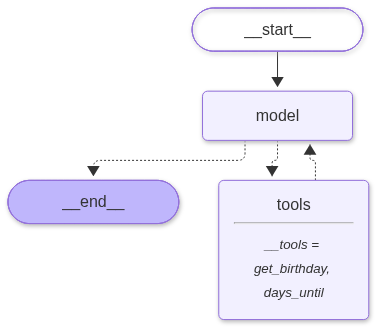

In [26]:
from IPython.display import Image

Image(agent.get_graph().draw_mermaid_png())

How to read the drawing:

- `__start__` and `__end__` are where a run enters and leaves.
- `model` is the step that calls the model. `tools` is the step that runs our functions; its label lists them.
- The arrow from `__start__` to `model` is solid: every run begins with a model call.
- The other arrows are dotted, which means "only if". After a model call the run goes to `tools` if the reply asks
  for a tool, and to `__end__` if it does not.
- The arrow from `tools` back to `model` is the loop. It is dotted because a tool can be marked to end the run
  with its own result (`return_direct=True`). Ours are not, so `tools` always goes back to `model`.

### Watch a run one step at a time

Every message has a `type`: `human`, `ai` or `tool`. `describe` is a small helper for printing. It turns one message
into one line, using the two fields we read by hand in Part C: for a reply that asks for tools, the requests in
`tool_calls`; for anything else, the `text`.

In [27]:
def describe(message):
    """One line that says what a message holds."""
    if message.type == "ai" and message.tool_calls:
        return "asks for " + str([(call["name"], call["args"]) for call in message.tool_calls])
    return message.text

The agent's input is a dictionary with one key, `messages`: the conversation so far. We start it with one user
message.

`agent.stream(..., stream_mode="updates")` runs the agent and hands us each step as it finishes. Each step is a
dictionary with one entry. Its key is the node's name, and its value holds, under `messages`, the list of messages
that node added.

Before you run it: which tool will the model ask for first, and what will it pass to the second one?

In [28]:
QUESTION = "How many days until Maya's birthday?"

for step in agent.stream({"messages": [{"role": "user", "content": QUESTION}]}, stream_mode="updates"):
    for node, update in step.items():
        for message in update["messages"]:
            print(f"{node:5} | {describe(message)}")

model | asks for [('get_birthday', {'name': 'Maya'})]
TOOL CALLED: get_birthday(Maya)
tools | 14 March


model | asks for [('days_until', {'day': 14, 'month': 3})]
TOOL CALLED: days_until(14, 3)
tools | 121


model | Maya’s birthday is 121 days away.


Three turns:

1. `model` asks for `get_birthday` with `{'name': 'Maya'}`.
2. `tools` runs it and returns `14 March`.
3. `model` asks for `days_until` with day 14 and month 3. Nobody typed 14 and 3: the model took them from the
   first tool's result, as the docstring asked.
4. `tools` runs it and returns 121.
5. `model` writes the answer: *Maya’s birthday is 121 days away.*

In [29]:
result = agent.invoke(
    {"messages": [{"role": "user", "content": "Whose birthday comes first in the year, Maya's or Sam's?"}]}
)

for message in result["messages"]:
    print(f"{message.type:5} | {describe(message)}")

TOOL CALLED: get_birthday(Maya)
TOOL CALLED: get_birthday(Sam)


human | Whose birthday comes first in the year, Maya's or Sam's?
ai    | asks for [('get_birthday', {'name': 'Maya'}), ('get_birthday', {'name': 'Sam'})]
tool  | 14 March
tool  | 22 July
ai    | Maya’s birthday comes first in the year.


Five messages. Each has a `type`: `human` is our question, `ai` is a reply from the model, and `tool` is a tool's
result.

- The first `ai` message asks for `get_birthday` twice in one reply, once for Maya and once for Sam.
- The two `tool` messages are the results: `14 March` and `2 July`.
- The last `ai` message is the answer: *Maya’s birthday comes first in the year.*

The two `TOOL CALLED` lines are printed first, and in our run Sam's came before Maya's: the agent runs the calls
of one reply at the same time.

**Notice** what the model did not do. It never asked for `days_until`: March comes before July, and that needs no
counting. Nothing in our code says which tools a question needs, or how many calls. The model chose.

The last message is the answer; `result["messages"][-1].text` reads it.

The picture below puts the two shapes of this notebook side by side.

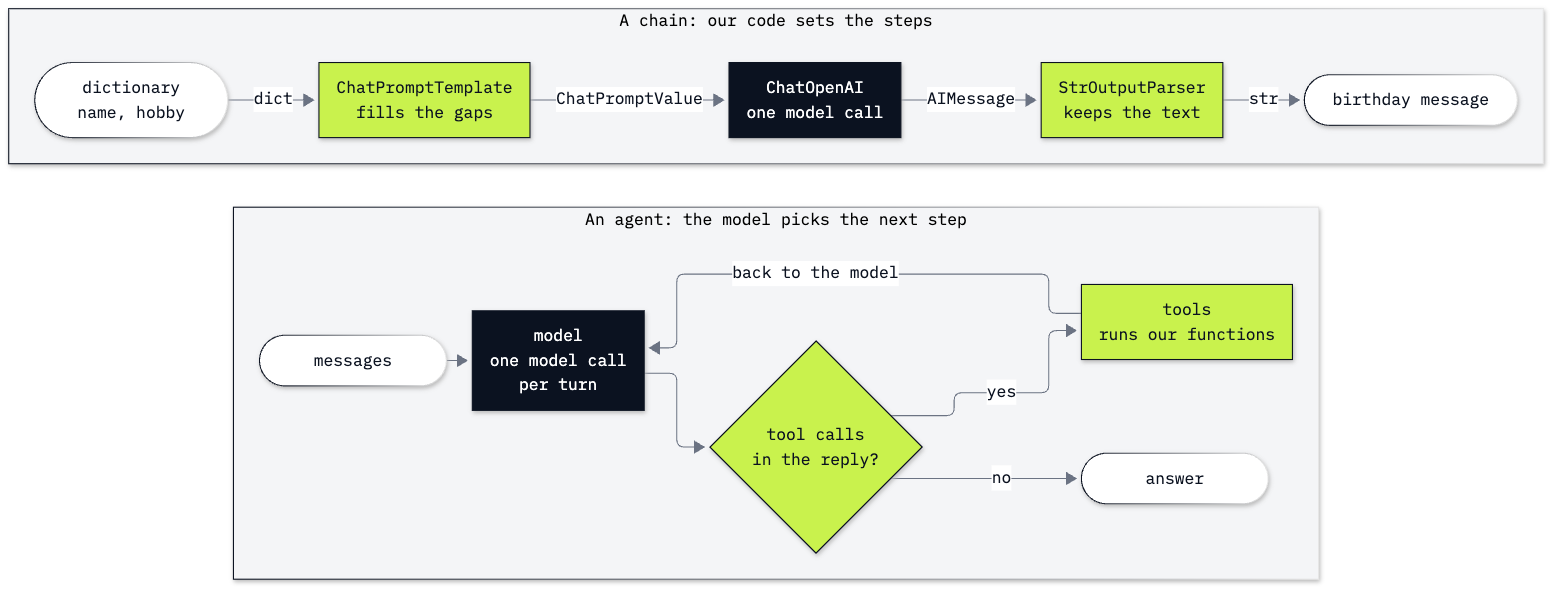

In [30]:
Image("resources/lab09_chain_and_agent.png", width=760)

Lime is our code, the dark boxes are the model. In the chain of Part A, our code fixed three steps and every input
takes the same path. In the agent, the path after each model call depends on what the model wrote.

**Checkpoint D.** `days_until(14, 3)` returns a number of days (ours: 121). The agent is a
`CompiledStateGraph` with the nodes `model` and `tools`. For Maya's birthday the steps are `model`, `tools`,
`model`, `tools`, `model`: `get_birthday` first, then `days_until` with day 14 and month 3, then the answer. For
the second question the model asks for `get_birthday` twice in one reply and never for `days_until`.

---

## Part E: Add web search, a tool that the model's provider runs

Our two tools reach only what we wrote: a dictionary of birthdays and a count of days. One more job for Maya needs
something from outside:

> We want to hike in the Grand Canyon on Maya's birthday. What is the weather usually like there at that time of year?

The birthday is in our contacts. The weather in the Grand Canyon, in Arizona, is on the web.

### A tool that is only a dictionary

This is the whole tool:

In [31]:
search_tool = {"type": "web_search"}
print(search_tool)

{'type': 'web_search'}


There is no Python function here. `web_search` is a tool that OpenAI, the model's provider, runs on its own
servers: the model asks for a search, OpenAI searches and reads pages, and the model writes its reply from what
came back, all inside one model call. The dictionary only switches the tool on.

That makes it different from `get_birthday` in three ways:

| | `get_birthday` | `web_search` |
|---|---|---|
| Who wrote it | we did | the model's provider |
| Where it runs | in our Python, in the agent's `tools` step | on the provider's servers, inside the model call |
| What we can look at | its `name`, `description` and `args`; we can call it by hand | nothing before the run; a record of the search in the reply |

### Our tool and the search tool, side by side

`create_agent` takes both in the same list. The system prompt says what the search is for and asks for a short
answer.

Before you run it: how many `TOOL CALLED` lines will print?

In [32]:
search_agent = create_agent(
    llm,
    [get_birthday, search_tool],
    system_prompt="You help me plan things for my friends. Search the web for anything about the world outside "
                  "my contacts. Answer in one or two short sentences.",
)

result = search_agent.invoke(
    {"messages": [{"role": "user", "content": "We want to hike in the Grand Canyon on Maya's birthday. "
                                              "What is the weather usually like there at that time of year?"}]}
)

for message in result["messages"]:
    print(f"{message.type:5} | {describe(message)}")

TOOL CALLED: get_birthday(Maya)


human | We want to hike in the Grand Canyon on Maya's birthday. What is the weather usually like there at that time of year?
ai    | asks for [('get_birthday', {'name': 'Maya'})]
tool  | 14 March
ai    | Maya’s birthday is **March 14**; in March, the South Rim is typically chilly—around **50°F by day and below freezing at night**, with possible snow or ice, while the inner canyon averages about **71°F by day and 48°F at night**. Conditions vary a lot with elevation, so dress in layers and check the forecast and trail conditions close to your hike. ([home.nps.gov](https://home.nps.gov/grca/learn/nature/weather.htm))


One `TOOL CALLED` line, `get_birthday(Maya)`, printed by our own function.

Read the messages. The model asked for `get_birthday` and got `14 March`. The next `ai` message is already the
answer. There is no `ai` message that asks for a search, and no `tool` message with search results: the search
happened inside the model's second call, on OpenAI's servers. The agent's `tools` step never ran it, and our code
printed nothing for it.

In our run the answer said that in March at the Grand Canyon the South Rim is typically *chilly—around 50°F by
day and below freezing at night*, while the inner canyon averages about *71°F by day and 48°F at night*, and it
ended with a link. Yours will differ: the pages a search finds change from day to day.

The record of the search is in the answer itself. Its `content` is a list of **content blocks**, small dictionaries
that each have a `type`. A reply holds such a list when its call went to the Responses API, one of OpenAI's two APIs for chat models. `ChatOpenAI` chose it for this call because the call carries tools; notebook 2 looks at the blocks closely. We print the type of each block and, for the two types we need, what they hold.

In [33]:
answer = result["messages"][-1]

for block in answer.content:
    print(block["type"])
    if block["type"] == "web_search_call":
        print("   searched for:", block["action"].get("queries"))
    if block["type"] == "text":
        for note in block["annotations"]:
            print("   source:", note["title"], "|", note["url"])

web_search_call
   searched for: ['Grand Canyon National Park March weather average temperatures precipitation South Rim inner canyon NPS']
web_search_call
   searched for: None
text
   source: Weather and Climate - Grand Canyon National Park (U.S. National Park Service) | https://home.nps.gov/grca/learn/nature/weather.htm


Two blocks:

- `web_search_call` is the record of the search. The model searched for *Grand Canyon National Park March
  weather average temperatures precipitation South Rim inner canyon NPS*. Nobody typed *March*: the model took
  it from our tool's `14 March`.
- `text` is the answer. Its `annotations` list the source it cites: *Weather and Climate - Grand Canyon
  National Park (U.S. National Park Service)*.

**What does this not prove?** The search found pages, and the model wrote a summary of them. Our code saw neither
the pages nor how the model read them. The numbers in the answer are only as good as that page and that summary:
open the link and check before you pack. (`utm_source=openai` at the end of the link is a label OpenAI adds to show
where the visit came from.)

Last, what the search added to the bill. Every `ai` message carries the token counts of its model call:

In [34]:
for message in result["messages"]:
    if message.type == "ai":
        print("input tokens:", message.usage_metadata["input_tokens"])

input tokens: 4548
input tokens: 14374


Two model calls. The second, which searched and read the pages, carried 14,374 input tokens. The first, which only
asked for `get_birthday`, already carried 4,548. The first call searched for nothing and still carried thousands of
input tokens: the search tool's own instructions travel with every request while it is switched on. OpenAI also
charges for each search, on top of the tokens (see its pricing page).

### Integrations: tools and services someone else wrote

LangChain connects to many outside services, and each connection is called an **integration**. Most ship as their
own package. `langchain-openai`, which this lab uses, is one; there are packages for other model vendors, for search
services, for databases and for cloud services. Most of them need an account or a key with the service. The search
in this part needs nothing beyond the OpenAI key, which is why we used it here.

Tools from any MCP server can also be loaded as LangChain tools with the
`langchain-mcp-adapters` package. And an older package that held many integrations together, `langchain-community`,
is being retired, so prefer an integration's own package. The full list is on LangChain's
[integrations page](https://docs.langchain.com/oss/python/integrations/providers/overview).

**Checkpoint E.** One `TOOL CALLED` line, for `get_birthday(Maya)`, and no `tool` message for the search; an answer
with Maya's birthday and the usual weather in the Grand Canyon in March, with at least one link; a `web_search_call` block
before the `text` block. The weather, the page and the wording will differ on your run. Two model calls, the first
already carrying thousands of input tokens (ours: 4,548 and 14,374).

---

## Part F (optional): Swap the model in the chain for another vendor's

A chain is a list of steps, and a step can be replaced. Here we replace the model of Part A's chain with a Gemini
model from Google, and keep the same `prompt` and the same `parser`.

LangChain has a model class for each vendor (for Gemini, `ChatGoogleGenerativeAI` in the `langchain-google-genai`
package, which this repository does not install). Google also serves Gemini at an address that accepts requests in the
same format as OpenAI's API, so `ChatOpenAI` can call it when we give it that address as `base_url`.

⚠️ This part needs a second key, `GEMINI_API_KEY`, in `.env`. It is optional: without the key the cell prints a
message and skips, and nothing in notebook 2 depends on it. The Gemini model name is `GEMINI_MODEL` in
`models.env`.

In [35]:
GEMINI_KEY = os.environ.get("GEMINI_API_KEY") or local.get("GEMINI_API_KEY")

if not GEMINI_KEY:
    print("No GEMINI_API_KEY in .env: skipping this optional part.")
else:
    gemini = ChatOpenAI(
        model=settings["GEMINI_MODEL"],
        api_key=GEMINI_KEY,
        base_url="https://generativelanguage.googleapis.com/v1beta/openai/",
        timeout=60,
    )

    gemini_chain = prompt | gemini | parser

    print(gemini_chain.invoke({"name": "Maya", "hobby": "hiking"}))

Wishing a very happy birthday to Maya—may your year ahead be filled with peak experiences, beautiful trails, and new summits!


With the key in place, the saved run shows a birthday message for Maya in another model's words: *Wishing a very
happy birthday to Maya—may your year ahead be filled with peak experiences, beautiful trails, and new summits!* The
template filled the two gaps, the parser stripped the message to a string, and only the model changed.

## What you can do now

- Call a chat model with `ChatOpenAI`, and join a template, model, and parser into a chain with `|` (Part A).
- Extract typed fields with `with_structured_output`, and check what the schema validates against what the model invents (Part B).
- Bind Python functions as tools and run a tool round trip by hand (Part C).
- Build a loop with `create_agent`, draw its graph, and inspect streamed steps (Part D).
- Run provider-executed web search beside local tools and read URL citations in content blocks (Part E).

---

## Troubleshooting

| What you see | What it usually means | What to try |
|---|---|---|
| `AuthenticationError` | the API key is missing, expired or rejected | check that `.env` holds `OPENAI_API_KEY=sk-...` without quotes or spaces |
| `KeyError: 'name'` or `'hobby'` | `prompt.invoke` did not get all the template's variables | pass a dictionary with both keys |
| `ValidationError` | `Event` received a value of the wrong type | check the fields against the class; `day` and `time` are strings |
| `No birthday saved for ...` in a tool result | the name is not a key of `BIRTHDAYS` | ask about Maya, Sam or Lina, or add the name to the dictionary |
| Mermaid drawing fails or times out | the mermaid.ink service is unreachable | skip the cell; the agent runs the same without the picture |

---

## Challenge

Try these after Parts A to E:

1. **Extract two events at once.** Give `with_structured_output` a list of two text messages: *Football Saturday 6pm at
   the school pitch, bring water, tell Leo and Lina* and *Lina's graduation Sunday 11am, bring flowers*.
   Expected: two `Event` objects with the times `18:00` and `11:00`; `tell` is `['Leo', 'Lina']` for the first
   and empty for the second.
2. **Add a hobby lookup.** Add a third tool, `get_hobby(name)`, that returns what a friend likes to do. Give the agent
   it. Build a new agent with the three tools and ask: *Maya's birthday is coming up. How many days do I have, and
   what could I get her?* Expected: the model asks for `get_birthday` and `get_hobby` first, then for `days_until`,
   and suggests a gift that fits the hobby. The solution is in `solved/09a_meet_langchain_solution.ipynb`.

## Going further

3. **Batch birthday messages.** Run Part A's chain over three friends at once with `chain.batch`:

In [36]:
friends = [
    {"name": "Maya", "hobby": "hiking"},
    {"name": "Sam", "hobby": "chess"},
    {"name": "Lina", "hobby": "baking"},
]

for text in chain.batch(friends):
    print(text)

Happy birthday, Maya—may your year be full of beautiful trails, breathtaking views, and joyful adventures!
Happy birthday, Sam—may your year be full of brilliant moves and checkmates!
Happy birthday, Lina—may your day be as sweet as the treats you love to bake!


**Watch a reply arrive.** On a chain, `stream` hands us the reply in small pieces while the model is still
writing. In Part D the agent's `stream` handed us whole steps, because we asked for `stream_mode="updates"`.
`end=""` prints the pieces on one line.

In [37]:
for piece in chain.stream({"name": "Maya", "hobby": "hiking"}):
    print(piece, end="", flush=True)

Happy

 birthday

,

 Maya

—

may

... (11 outputs left out)

 and

 happy

 adventures

!

**See the request LangChain sends.** In Part B we said that `with_structured_output` sends the class to the API.
To see it, we give a second model object its own HTTP client with an **event hook**: a function the client calls
with every request, just before it is sent. Ours is `sent.append`, so each request lands in a list. Ordinary code
does not need this; it is here only so we can look.

In [38]:
import openai

sent = []
watched_llm = ChatOpenAI(
    model=MODEL,
    reasoning_effort=EFFORT,
    timeout=60,
    http_client=openai.DefaultHttpxClient(event_hooks={"request": [sent.append]}),
)

watched_llm.with_structured_output(Event).invoke(MESSAGE)

body = json.loads(sent[0].content)
shape = body["response_format"]["json_schema"]
print("sent to:  ", sent[0].url.path)
print("keys sent:", list(body))
print("format:   ", shape["name"], "| strict:", shape["strict"], "| required:", shape["schema"]["required"])

sent to:   /v1/chat/completions
keys sent: ['model', 'stream', 'messages', 'reasoning_effort', 'response_format']
format:    Event | strict: True | required: ['title', 'day', 'time', 'bring', 'tell']


Three lines about the one request that was sent:

- It went to `/v1/chat/completions`, an address of OpenAI's API.
- Besides the model and the messages, it carried a `response_format`.
- That format is named `Event`, after our class. It lists all five fields as required, and it is `strict`: the API
  returns JSON that fits the class exactly. This is why `tell` came back as a list.

More to read:

- **What a chain cost.** A chain that ends in a parser returns a string, so the token counts of the `AIMessage` are
  gone. `get_usage_metadata_callback` (from `langchain_core.callbacks`) collects them for every model call made
  inside a `with` block; multiply by the prices in `models.env` for the cost.
- **Trace a run.** LangSmith, LangChain's hosted tracing service, shows every step of a chain or an agent on a web
  page. It needs an account; bonus lab B7 uses it.

## Resources

- [LangChain: overview](https://docs.langchain.com/oss/python/langchain/overview): the documentation's home
- [Models](https://docs.langchain.com/oss/python/langchain/models): chat models, `invoke`, `batch` and `stream`
- [Messages](https://docs.langchain.com/oss/python/langchain/messages): `HumanMessage`, `AIMessage`, `ToolMessage`
  and `.text`
- [Structured output](https://docs.langchain.com/oss/python/langchain/structured-output): `with_structured_output`
  and typed answers from an agent
- [Tools](https://docs.langchain.com/oss/python/langchain/tools): `tool`, docstrings and type hints as the
  description
- [Agents](https://docs.langchain.com/oss/python/langchain/agents): `create_agent` and its loop
- [ChatOpenAI](https://docs.langchain.com/oss/python/integrations/chat/openai): the OpenAI model class, its
  settings and the tools OpenAI runs, such as web search
- [Integrations](https://docs.langchain.com/oss/python/integrations/providers/overview): every service LangChain
  connects to, and the package for each
- [Pydantic: models](https://docs.pydantic.dev/latest/concepts/models/): classes with typed fields

Next: [notebook 2, LangChain at the Chinook desk](09b_langchain_at_the_desk.ipynb).